# Task D — E-commerce review figure

This notebook audits the raw file **before plotting**, resolves the
timestamp convention explicitly, and builds the required 2×2 figure.
Hourly columns are flows. The observed daily sum is kept separate from a
weekday-hour-median estimate that fills missing hours for the trend only.
The main trend is a **7-day centred mean**—a retrospective weekly-cycle
smoother, fixed before looking at the plotted direction.

**Source:** synthetic Week 4 course data in `assignments/data/`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

HERE = Path.cwd()
WEEK4_DIR = HERE if (HERE / "assignments" / "data").exists() else HERE / "week4"
ASSIGNMENTS_DIR = WEEK4_DIR / "assignments"
DATA_DIR = ASSIGNMENTS_DIR / "data"
sys.path.insert(0, str(ASSIGNMENTS_DIR))
from tslib import PALETTE, style_defaults, save_fig, audit_index

style_defaults()

from tslib import treemap, save_fig, rollup_other

raw = pd.read_csv(DATA_DIR / "sessions_hourly.csv")
print("1) df.info()")
raw.info()
print("\n2) df.describe().T")
display(raw.describe(include="all").T)
print("\n3) df.device.value_counts()")
display(raw.device.value_counts(dropna=False))
print("\n4) df.ts.head(10).tolist()")
print(raw.ts.head(10).tolist())

1) df.info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12670 entries, 0 to 12669
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ts           12670 non-null  object
 1   sessions     12670 non-null  int64 
 2   orders       12670 non-null  int64 
 3   revenue_pkr  12670 non-null  int64 
 4   device       12670 non-null  object
dtypes: int64(3), object(2)
memory usage: 495.1+ KB

2) df.describe().T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ts,12670,12505,12/07/2024 08:00,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sessions,12670.0,NaN,NaN,NaN,947.951381,646.882994,-1.0,435.0,756.0,1368.0,9811.0
orders,12670.0,NaN,NaN,NaN,30.016732,20.089492,4.0,14.0,24.0,42.0,304.0
revenue_pkr,12670.0,NaN,NaN,NaN,132564.968824,100150.706234,10350.0,58036.5,102359.0,182232.25,1652881.0
device,12670,6,Mobile,6994,NaN,NaN,NaN,NaN,NaN,NaN,NaN



3) df.device.value_counts()


device
Mobile     6994
Desktop    3452
mobile      883
Tablet      777
desktop     318
MOBILE      246
Name: count, dtype: int64


4) df.ts.head(10).tolist()
['2024-04-29 11:00:00', '2024-10-26 05:00:00', '2025-08-04 20:00:00', '2024-10-05 19:00:00', '2025-01-22 20:00:00', '05/10/2024 09:00', '2024-08-11 15:00:00', '12/04/2025 10:00', '2024-07-24 02:00:00', '2025-03-27 11:00:00']


## Timestamp resolution and index audit

The timestamp column contains ISO `YYYY-MM-DD HH:MM:SS` strings and
slash-formatted `DD/MM/YYYY HH:MM` strings. Parse each format explicitly;
the slash records include day values greater than 12, and day-first parsing
keeps the full span inside the documented April 2024–September 2025 window.
`format="mixed"` is not used because a successful parse can still assign
ambiguous dates to the wrong month.

In [2]:
iso = raw["ts"].str.match(r"^\d{4}-\d{2}-\d{2} ")
parsed = pd.Series(pd.NaT, index=raw.index, dtype="datetime64[ns]")
parsed.loc[iso] = pd.to_datetime(raw.loc[iso, "ts"], format="%Y-%m-%d %H:%M:%S")
parsed.loc[~iso] = pd.to_datetime(raw.loc[~iso, "ts"], format="%d/%m/%Y %H:%M")
assert parsed.notna().all(), "Unparsed timestamps require investigation."
print(f"ISO rows={int(iso.sum()):,}; slash rows={int((~iso).sum()):,}; "
      f"day-first evidence (first field > 12)={int(raw.loc[~iso, 'ts'].str[:2].astype(int).gt(12).sum())}")

parsed_raw = raw.assign(ts=parsed).set_index("ts")
print("Raw index audit (before sorting, deduplication, or reindexing):")
raw_audit = audit_index(parsed_raw, "h")
display(raw_audit)
print("The original row order is shuffled; sorting is required before time operations.")

ISO rows=9,019; slash rows=3,651; day-first evidence (first field > 12)=2151
Raw index audit (before sorting, deduplication, or reindexing):


{'dtype_ok': True,
 'monotonic': False,
 'n_rows': 12670,
 'n_duplicated': 286,
 'n_missing': 312,
 'missing_dates': ['2024-05-18 00:00:00',
  '2024-05-18 01:00:00',
  '2024-05-18 02:00:00',
  '2024-05-18 03:00:00',
  '2024-05-18 04:00:00',
  '2024-05-18 05:00:00',
  '2024-05-18 06:00:00',
  '2024-05-18 07:00:00',
  '2024-05-18 08:00:00',
  '2024-05-18 09:00:00',
  '2024-05-18 10:00:00',
  '2024-05-18 11:00:00'],
 'span': ('2024-04-01 00:00:00', '2025-09-11 23:00:00'),
 'partial_tail': False,
 'tail_period': '2025-09-11',
 'tail_count': 24}

The original row order is shuffled; sorting is required before time operations.


## Clean rows and preserve missing time

In [3]:
clean = raw.assign(ts=parsed, device=raw["device"].str.strip().str.title()).copy()
initial_rows = len(clean)
invalid_session = clean["sessions"].lt(0)
invalid_rows = int(invalid_session.sum())
clean = clean.loc[~invalid_session].copy()
before_dedup = len(clean)
duplicate_time = clean["ts"].duplicated(keep="first")
duplicate_rows = int(duplicate_time.sum())
clean = clean.loc[~duplicate_time].set_index("ts").sort_index()

expected_hours = pd.date_range(clean.index.min().normalize(),
                               clean.index.max().normalize() + pd.Timedelta(hours=23), freq="h")
hourly_sessions = clean["sessions"].astype(float).reindex(expected_hours)
hour_coverage = hourly_sessions.notna().resample("D").sum()
hour_profile = clean["sessions"].groupby([clean.index.dayofweek, clean.index.hour]).median()
hourly_estimate = hourly_sessions.copy()
missing_hours = hourly_estimate.index[hourly_estimate.isna()]
missing_keys = pd.MultiIndex.from_arrays([missing_hours.dayofweek, missing_hours.hour])
hourly_estimate.loc[missing_hours] = [hour_profile.loc[key] for key in missing_keys]
observed_daily = hourly_sessions.resample("D").sum(min_count=1).asfreq("D")
daily_sessions = hourly_estimate.resample("D").sum(min_count=24).asfreq("D")
daily_sessions.name = "sessions_per_day"

audit_table = pd.DataFrame(
    [
        ("Raw rows", initial_rows, "input"),
        ("Negative session sentinels removed", invalid_rows, "sessions < 0; row invalid"),
        ("Duplicate timestamps removed", duplicate_rows, "first source row retained"),
        ("Unique timestamps after cleaning", len(clean), "one observation per hour"),
        ("Missing hourly bins", int(hourly_sessions.isna().sum()), "kept as NaN after reindex"),
        ("Hourly values imputed for daily estimate", len(missing_hours), "weekday × hour median"),
        ("Days with incomplete observed coverage", int(hour_coverage.lt(24).sum()), "flagged; observed daily sum stays separate"),
    ],
    columns=["Check", "Count", "Rule"],
)
display(audit_table)
print("Normalized device labels:", clean.device.value_counts().to_dict())
print("Final calendar span:", clean.index.min(), "to", clean.index.max())
print("Partial final month:", daily_sessions.index.max().strftime("%B %Y"),
      f"({daily_sessions.index.max().day} observed calendar days of "
      f"{daily_sessions.index.max().days_in_month}); retained and explicitly marked.")
fault_summary = pd.DataFrame(
    [
        ("1. Mixed timestamp formats", f"{int(iso.sum()):,} ISO + {int((~iso).sum()):,} slash dates", "Parse each explicit format"),
        ("2. Inconsistent device labels", f"{raw.device.nunique()} raw labels → {clean.device.nunique()} normalized labels", "Strip whitespace; title-case"),
        ("3. Negative session sentinel", f"{invalid_rows:,} rows with sessions < 0", "Remove invalid flow rows"),
        ("4. Shuffled timestamp order", str(raw_audit["monotonic"]), "Sort parsed DatetimeIndex"),
        ("5. Duplicate timestamps", f"{raw_audit['n_duplicated']:,} before cleaning", "Keep first timestamp occurrence"),
        ("6. Missing hourly periods", f"{raw_audit['n_missing']:,} before cleaning", "Reindex hourly; flag and estimate separately"),
    ],
    columns=["Issue", "Evidence", "Rule"],
)
display(fault_summary)
print("Coverage note (separate from the six faults): the extract ends partway through September 2025.")

,Check,Count,Rule
0,Raw rows,12670,input
1,Negative session sentinels removed,290,sessions < 0; row invalid
2,Duplicate timestamps removed,283,first source row retained
3,Unique timestamps after cleaning,12097,one observation per hour
4,Missing hourly bins,599,kept as NaN after reindex
5,Hourly values imputed for daily estimate,599,weekday × hour median
6,Days with incomplete observed coverage,235,flagged; observed daily sum stays separate


Normalized device labels: {'Mobile': 7759, 'Desktop': 3599, 'Tablet': 739}
Final calendar span: 2024-04-01 01:00:00 to 2025-09-11 23:00:00
Partial final month: September 2025 (11 observed calendar days of 30); retained and explicitly marked.


,Issue,Evidence,Rule
0,1. Mixed timestamp formats,"9,019 ISO + 3,651 slash dates",Parse each explicit format
1,2. Inconsistent device labels,6 raw labels → 3 normalized labels,Strip whitespace; title-case
2,3. Negative session sentinel,290 rows with sessions < 0,Remove invalid flow rows
3,4. Shuffled timestamp order,False,Sort parsed DatetimeIndex
4,5. Duplicate timestamps,286 before cleaning,Keep first timestamp occurrence
5,6. Missing hourly periods,312 before cleaning,Reindex hourly; flag and estimate separately


Coverage note (separate from the six faults): the extract ends partway through September 2025.


**Cleaning decisions.** (1) Normalize `device` by stripping whitespace and
title-casing labels. (2) Keep one row per timestamp, retaining the first
source occurrence; the file is designed for one hourly observation.
(3) Remove negative `sessions` sentinel rows—negative visits cannot be
meaningful flows. (4) Reindex the cleaned hourly flow to the complete hourly
calendar and leave absent hours as `NaN`. (5) Preserve observed partial-day
sums separately; for a comparable daily estimate only, fill absent/sentinel
hours with the median for that weekday and hour. Flag every day with
incomplete observed coverage and show the raw observed sums as well. The
heatmap uses complete days only. No plausible high-traffic event is clipped.
The September extract is retained but flagged as partial; it is not
compared with a complete monthly total.

## Catalogue checks, duplicate SKU, negative net revenue

In [4]:
catalogue_raw = pd.read_csv(DATA_DIR / "revenue_catalogue.csv")
sku_dups = catalogue_raw[catalogue_raw.duplicated("sku", keep=False)].sort_values("sku")
catalogue = catalogue_raw.drop_duplicates("sku", keep="first").copy()
negative_mask = catalogue["net_revenue_pkr_m"].lt(0)
negative_rows = catalogue.loc[negative_mask]
positive = catalogue.loc[~negative_mask & catalogue["net_revenue_pkr_m"].gt(0)].copy()

parent_counts = catalogue.groupby("sku")["category"].nunique()
assert parent_counts.max() == 1
assert catalogue.groupby("subcategory")["category"].nunique().max() == 1
subcategory_revenue = positive.groupby(["category", "subcategory"])["net_revenue_pkr_m"].sum()
category_revenue = subcategory_revenue.groupby(level="category").sum()
positive_total = float(subcategory_revenue.sum())
shares = (subcategory_revenue.droplevel("category") / positive_total * 100).sort_values(ascending=False)

print(f"Catalogue rows={len(catalogue_raw)}; duplicate SKU rows removed={len(catalogue_raw)-len(catalogue)}")
display(sku_dups[["category", "subcategory", "sku", "net_revenue_pkr_m"]])
print(f"Negative net rows excluded from area={len(negative_rows)}; combined net value="
      f"{negative_rows.net_revenue_pkr_m.sum():.4f} PKR m. These negatives are reported, not drawn as area.")
print(f"Positive revenue total={positive_total:,.4f} PKR m; positive SKUs={len(positive)}")
print("Category totals (PKR m):")
display(category_revenue.sort_values(ascending=False).round(2).to_frame())

shares_file = pd.read_csv(DATA_DIR / "shares_eight.csv").set_index("subcategory")["share_pct"]
share_check = pd.concat([shares.rename("catalogue_share_pct"),
                         shares_file.rename("reference_share_pct")], axis=1)
share_check["difference_pp"] = share_check.catalogue_share_pct - share_check.reference_share_pct
display(share_check.round(2))
assert share_check.difference_pp.abs().max() <= 0.3
assert abs(shares_file.sum() - 100) < 1e-6

Catalogue rows=345; duplicate SKU rows removed=1


,category,subcategory,sku,net_revenue_pkr_m
126,Audio & Imaging,Audio,SKU-0127,14.8275
344,Lifestyle,Wearables,SKU-0127,14.8275


Negative net rows excluded from area=7; combined net value=-1.0693 PKR m. These negatives are reported, not drawn as area.
Positive revenue total=1,712.4508 PKR m; positive SKUs=336
Category totals (PKR m):


,net_revenue_pkr_m
category,
Mobile,652.01
Audio & Imaging,400.00
Lifestyle,348.44
Computing,311.99


,catalogue_share_pct,reference_share_pct,difference_pp
subcategory,,,
Phones,24.75,24.6,0.15
Laptops,18.22,18.4,-0.18
Audio,14.98,15.0,-0.02
Accessories,13.33,13.1,0.23
Footwear,10.99,11.2,-0.21
Wearables,9.36,9.2,0.16
Cameras,5.97,6.1,-0.13
Drones,2.41,2.4,0.01


The duplicated SKU is retained only at its first source parent so it cannot
be counted twice in the hierarchy. All seven negative net-revenue SKUs are
excluded from area (negative values have no area) and their combined value
is disclosed above. The treemap uses positive net revenue by subcategory;
the eight-share self-check must be within 0.3 percentage points.

## Four-panel figure — one question per panel

Other roll-up: no categories below 1.0%


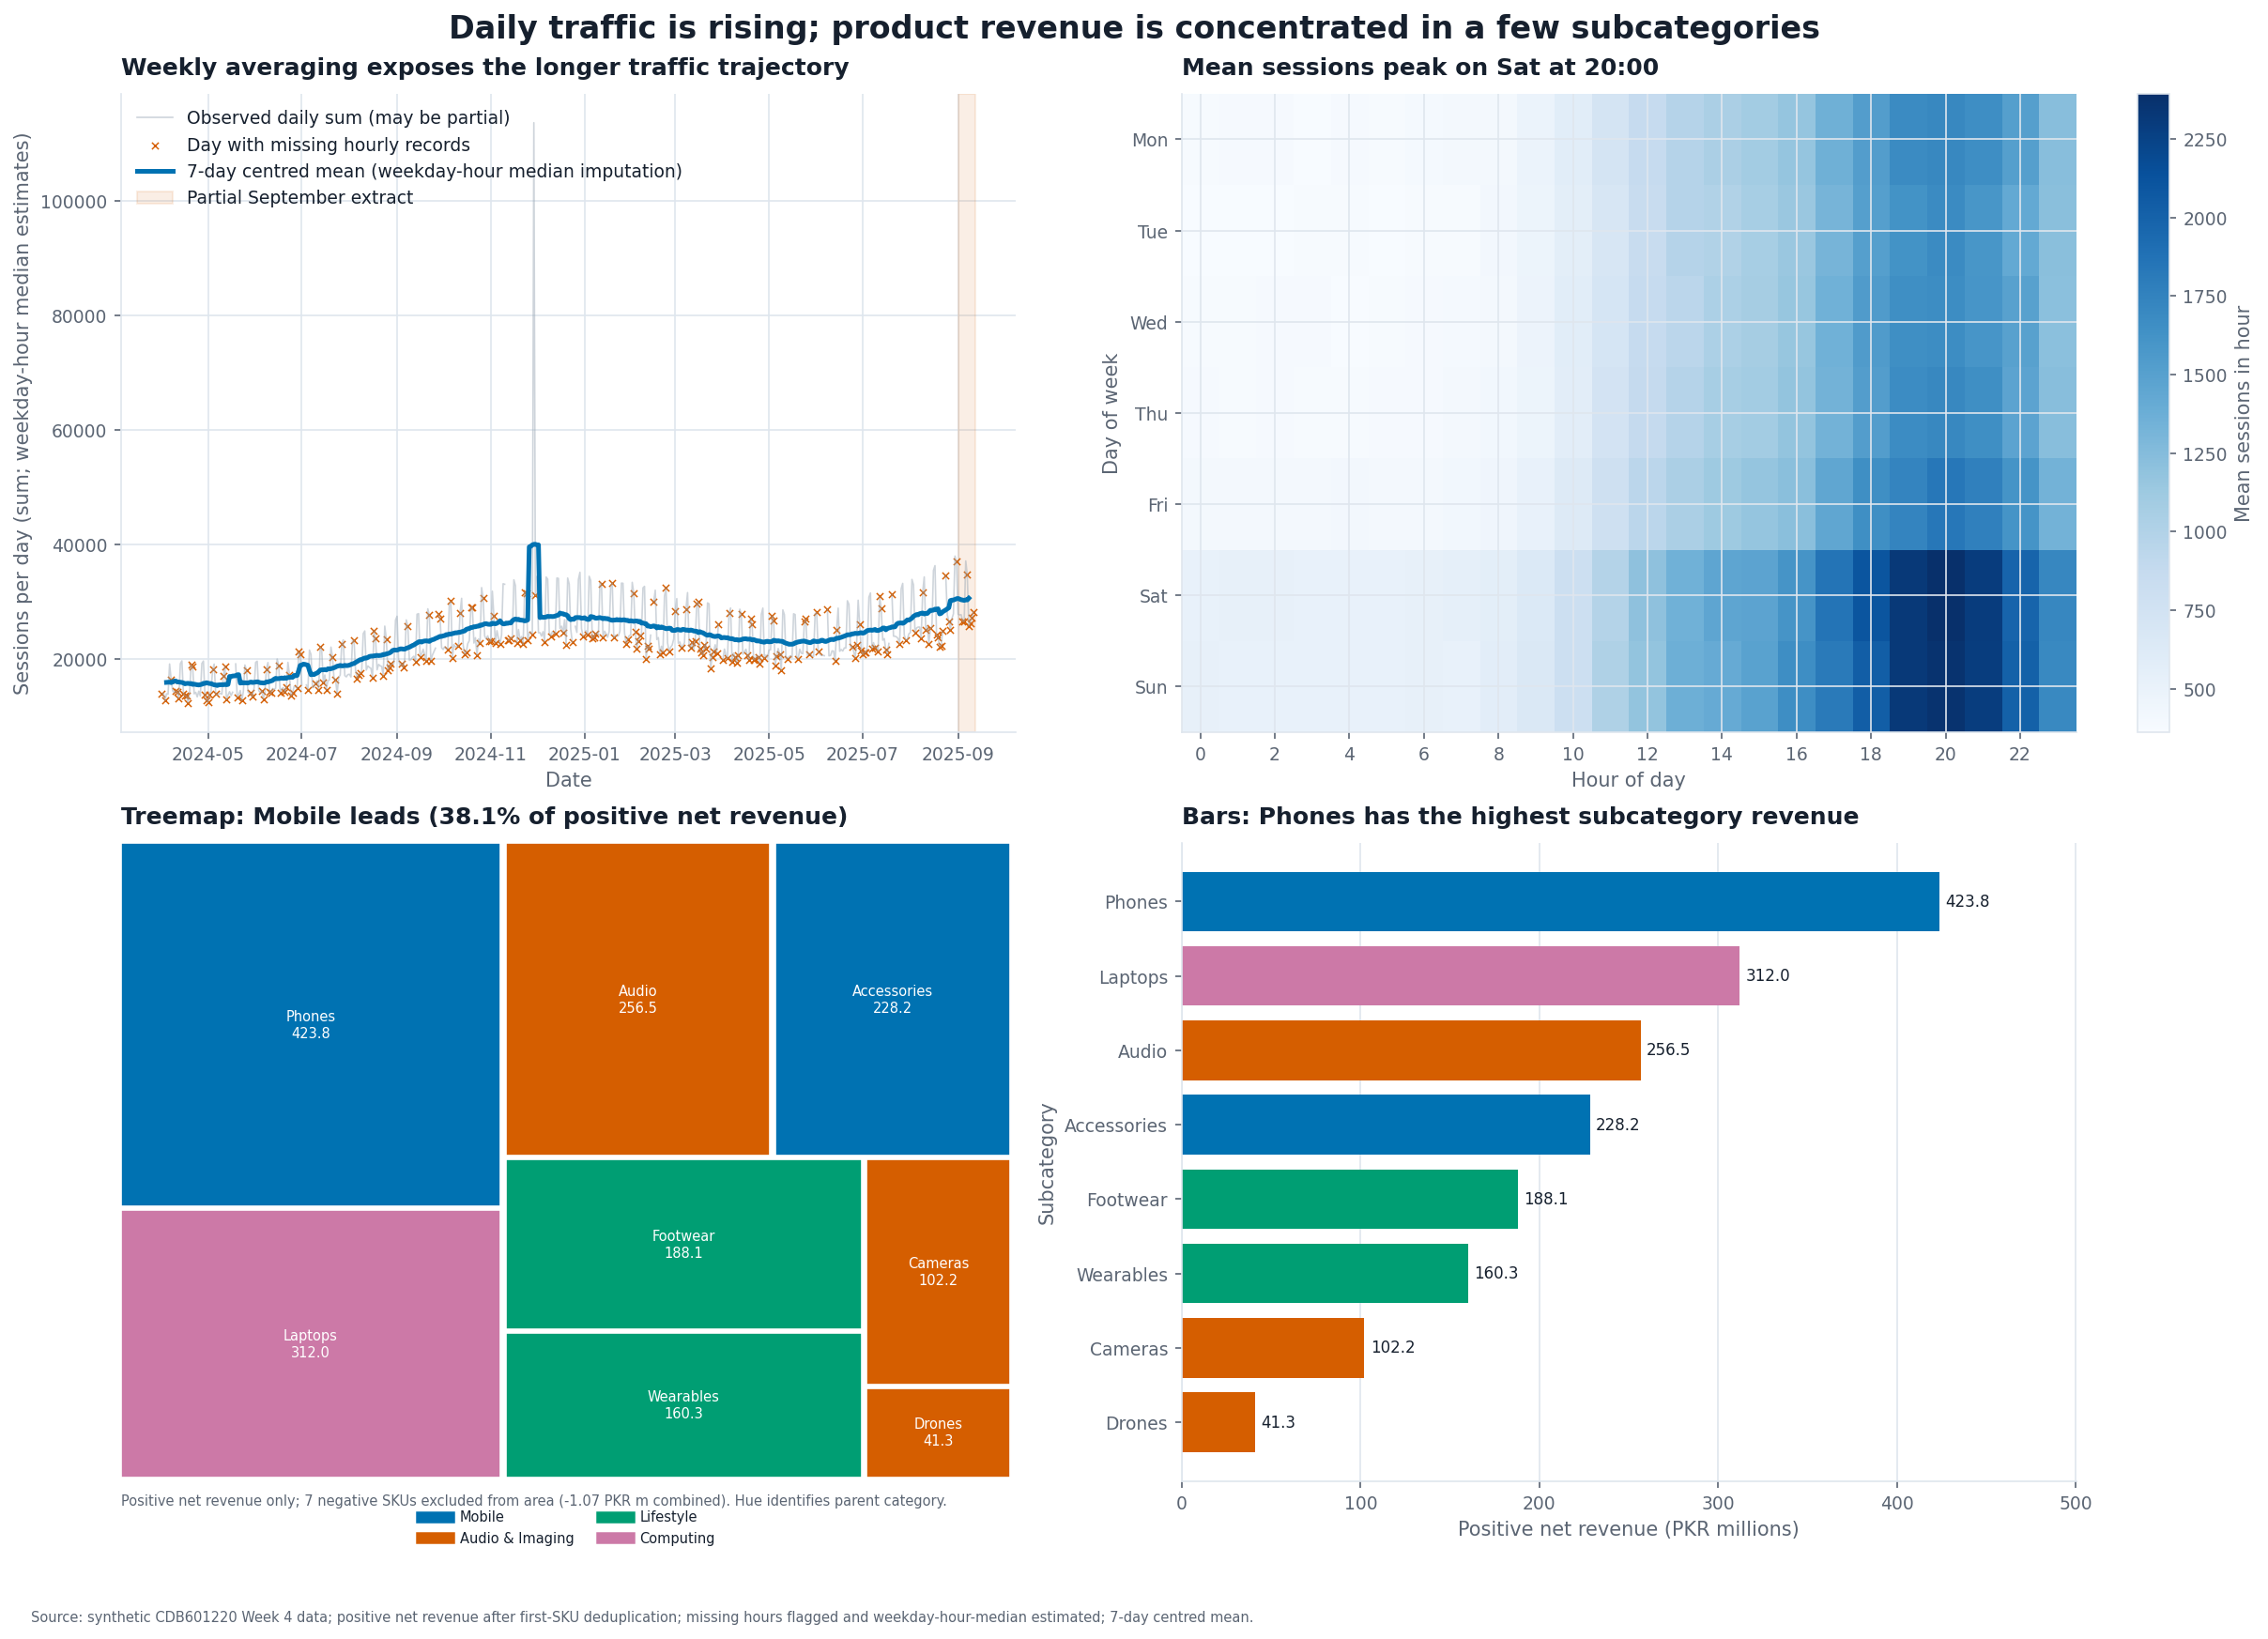

Exported: D:\7_Semester\data-visualization\week4\taskD_review.png | dpi=300 | tight bounding box


In [5]:
# Panel 2 uses only complete days so each day/hour mean has the same
# 24-hour observed coverage. Partial daily sums are marked in panel 1.
complete_days = hour_coverage.index[hour_coverage.eq(24)]
complete_hourly = hourly_sessions.loc[hourly_sessions.index.normalize().isin(complete_days)]
heat = (complete_hourly.rename("sessions")
        .to_frame()
        .assign(weekday=lambda x: x.index.dayofweek, hour=lambda x: x.index.hour)
        .pivot_table(index="weekday", columns="hour", values="sessions", aggfunc="mean")
        .reindex(index=range(7), columns=range(24)))
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
peak_weekday, peak_hour = np.unravel_index(np.nanargmax(heat.to_numpy()), heat.shape)

subcats = subcategory_revenue.reset_index()
subcategory_values = subcategory_revenue.droplevel("category")
rolled_subcategories, other_note = rollup_other(subcategory_values, min_share_pct=1.0)
color_slots = PALETTE["series"] + [PALETTE["series_4th"]]
parent_order = list(category_revenue.sort_values(ascending=False).index)
parent_colors = {name: color_slots[i] for i, name in enumerate(parent_order)}
parent_for_subcategory = (
    subcategory_revenue.index.to_frame(index=False)
    .drop_duplicates()
    .set_index("subcategory")["category"]
)
rect_colors = [parent_colors[name] for name in subcats["category"]]
largest_category = category_revenue.idxmax()
largest_category_share = category_revenue.max() / positive_total * 100
largest_subcategory = shares.idxmax()

fig, axes = plt.subplots(2, 2, figsize=(16, 11), constrained_layout=True)
fig.suptitle("Daily traffic is rising; product revenue is concentrated in a few subcategories",
             fontsize=16, fontweight="bold")

ax = axes[0, 0]
ax.plot(observed_daily.index, observed_daily, color=PALETTE["muted"], alpha=.48,
        linewidth=.8, label="Observed daily sum (may be partial)")
partial_days = hour_coverage.index[hour_coverage.lt(24)]
ax.scatter(observed_daily.loc[partial_days].index, observed_daily.loc[partial_days],
           marker="x", s=12, color=PALETTE["highlight"], linewidths=.7,
           label="Day with missing hourly records")
trend = daily_sessions.rolling(7, center=True, min_periods=7).mean()
ax.plot(trend.index, trend, color=PALETTE["series"][0], linewidth=2.4,
        label="7-day centred mean (weekday-hour median imputation)")
ax.axvspan(pd.Timestamp("2025-09-01"), daily_sessions.index.max() + pd.Timedelta(days=1),
           color=PALETTE["highlight"], alpha=.10, label="Partial September extract")
ax.set(title="Weekly averaging exposes the longer traffic trajectory",
       xlabel="Date", ylabel="Sessions per day (sum; weekday-hour median estimates)")
ax.legend(loc="upper left")

ax = axes[0, 1]
image = ax.imshow(heat, aspect="auto", origin="upper", cmap=PALETTE["sequential"],
                  interpolation="nearest")
ax.set(title=f"Mean sessions peak on {weekday_names[peak_weekday]} at {peak_hour:02d}:00",
       xlabel="Hour of day", ylabel="Day of week")
ax.set_xticks(range(0, 24, 2))
ax.set_yticks(range(7), weekday_names)
fig.colorbar(image, ax=ax, label="Mean sessions in hour")

ax = axes[1, 0]
treemap(
    ax,
    sizes=subcats["net_revenue_pkr_m"],
    labels=[f"{r.subcategory}\n{r.net_revenue_pkr_m:,.1f}" for r in subcats.itertuples()],
    values=None,
    colors=rect_colors,
    fontsize=7,
)
ax.set_title(f"Treemap: {largest_category} leads ({largest_category_share:.1f}% of positive net revenue)")
ax.text(0, -0.02,
        f"Positive net revenue only; {len(negative_rows)} negative SKUs excluded from area "
        f"({negative_rows.net_revenue_pkr_m.sum():.2f} PKR m combined). "
        "Hue identifies parent category.",
        transform=ax.transAxes, ha="left", va="top", fontsize=7, color=PALETTE["ink_soft"])
handles = [plt.Line2D([0], [0], color=parent_colors[p], lw=6, label=p) for p in parent_order]
ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(.5, -.12),
          ncol=2, frameon=False, fontsize=7)

ax = axes[1, 1]
ordered = rolled_subcategories.sort_values(ascending=True)
bar_colors = [parent_colors[parent_for_subcategory[sub]] if sub in parent_for_subcategory.index
              else PALETTE["muted"] for sub in ordered.index]
bars = ax.barh(ordered.index, ordered.values, color=bar_colors)
ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8)
ax.set(title=f"Bars: {largest_subcategory} has the highest subcategory revenue",
       xlabel="Positive net revenue (PKR millions)", ylabel="Subcategory")
ax.set_xlim(0, ordered.max() * 1.18)
ax.grid(axis="y", visible=False)
print("Other roll-up:", other_note)

figure_path = WEEK4_DIR / "taskD_review.png"
source_note = ("Source: synthetic CDB601220 Week 4 data; positive net revenue after first-SKU deduplication; "
               "missing hours flagged and weekday-hour-median estimated; 7-day centred mean.")
save_fig(fig, figure_path, note=source_note)
plt.show()
print("Exported:", figure_path, "| dpi=300 | tight bounding box")

### Panel questions

1. **Daily line:** Is the underlying daily traffic trajectory changing once
   the weekly rhythm is reduced? Position on a shared time axis is the
   appropriate channel; raw measurements remain faintly visible.
2. **Weekday × hour heatmap:** At what time of week are sessions typically
   high? A sequential single-hue map encodes a non-negative magnitude; only
   complete days contribute.
3. **Treemap:** Where is the mass of positive subcategory revenue within
   parent categories? Area conveys hierarchy/coarse share; direct labels and
   the accompanying bars mitigate its weaker precision.
4. **Sorted bars:** By how much does each subcategory differ? Length and a
   common zero baseline support accurate ranking.

The treemap and bars use the same positive, deduplicated values. Four parent
categories map to four fixed hues; labels are printed on treemap blocks when
there is space. The fourth palette hue has reduced contrast, so values and
category names are directly labelled, with a legend.

## Cleaning record and output

The audit tables above document all row-level exclusions and the missing
calendar bins. Missing hours are retained as `NaN` on the hourly index and visibly marked
at daily resolution. The observed partial-day sums remain in light grey;
weekday-hour medians fill missing hourly values only in the separately
labelled trend estimate and are reported above. No SKU is removed without
a rule: one duplicate SKU row is resolved to its first occurrence and
negative net SKUs are reported outside the area chart. All eight
subcategories are retained, so **Other contains zero categories and has
zero value**; the hierarchy is rolled up at subcategory (not SKU) depth.

The static figure is exported as `week4/taskD_review.png` at 300 dpi before
display.